# Task 2 — Trends, and the spaghetti problem (`gapminder.csv`)

**Data:** 1,704 rows = 142 countries × 12 years (1952–2007, every 5 years). Columns: `country`, `continent`, `year`, `lifeExp`, `pop`, `gdpPercap`.

**Plan:** (1) make the messy 142-line chart on purpose and list what is wrong with it, (2) fix it twice: (a) aggregate by continent, (b) highlight three countries, (3) compare the two fixes, (4) answer "has the gap between the richest and poorest countries narrowed since 1952?", after looking at how skewed `gdpPercap` is and deciding whether a log scale is needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

candidates = [Path(p) for p in ["gapminder.csv", "data/gapminder.csv", "../data/gapminder.csv", "../gapminder.csv"]]
path = next((p for p in candidates if p.exists()), None) or next(Path("..").rglob("gapminder.csv"))
df = pd.read_csv(path)

# Sanity checks: the file should match the brief exactly
assert df.shape == (1704, 6), df.shape
assert df["country"].nunique() == 142 and df["year"].nunique() == 12
assert (df.groupby("country").size() == 12).all()
assert df.isna().sum().sum() == 0
print(f"Loaded {path}: {len(df):,} rows, {df['country'].nunique()} countries x {df['year'].nunique()} years ({df['year'].min()}-{df['year'].max()}), no missing values")

# Colours (used from Part 2 on). One neutral grey plus categorical slots in a fixed order; checked for colour-blind separation.
SURFACE, INK, INK2, GRID, GREY = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3", "#c4c3be"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"

def clean_style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
        "axes.edgecolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7,
        "axes.axisbelow": True, "font.size": 10,
        "text.parse_math": False,   # otherwise "$10,010 ... $37,152" is read as maths and the dollar signs disappear
    })

df.head()

Loaded gapminder.csv: 1,704 rows, 142 countries x 12 years (1952-2007), no missing values


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106


## Part 1 — The messy chart, on purpose
One line per country (all 142), default colours, a legend, and a title that just names the axes.

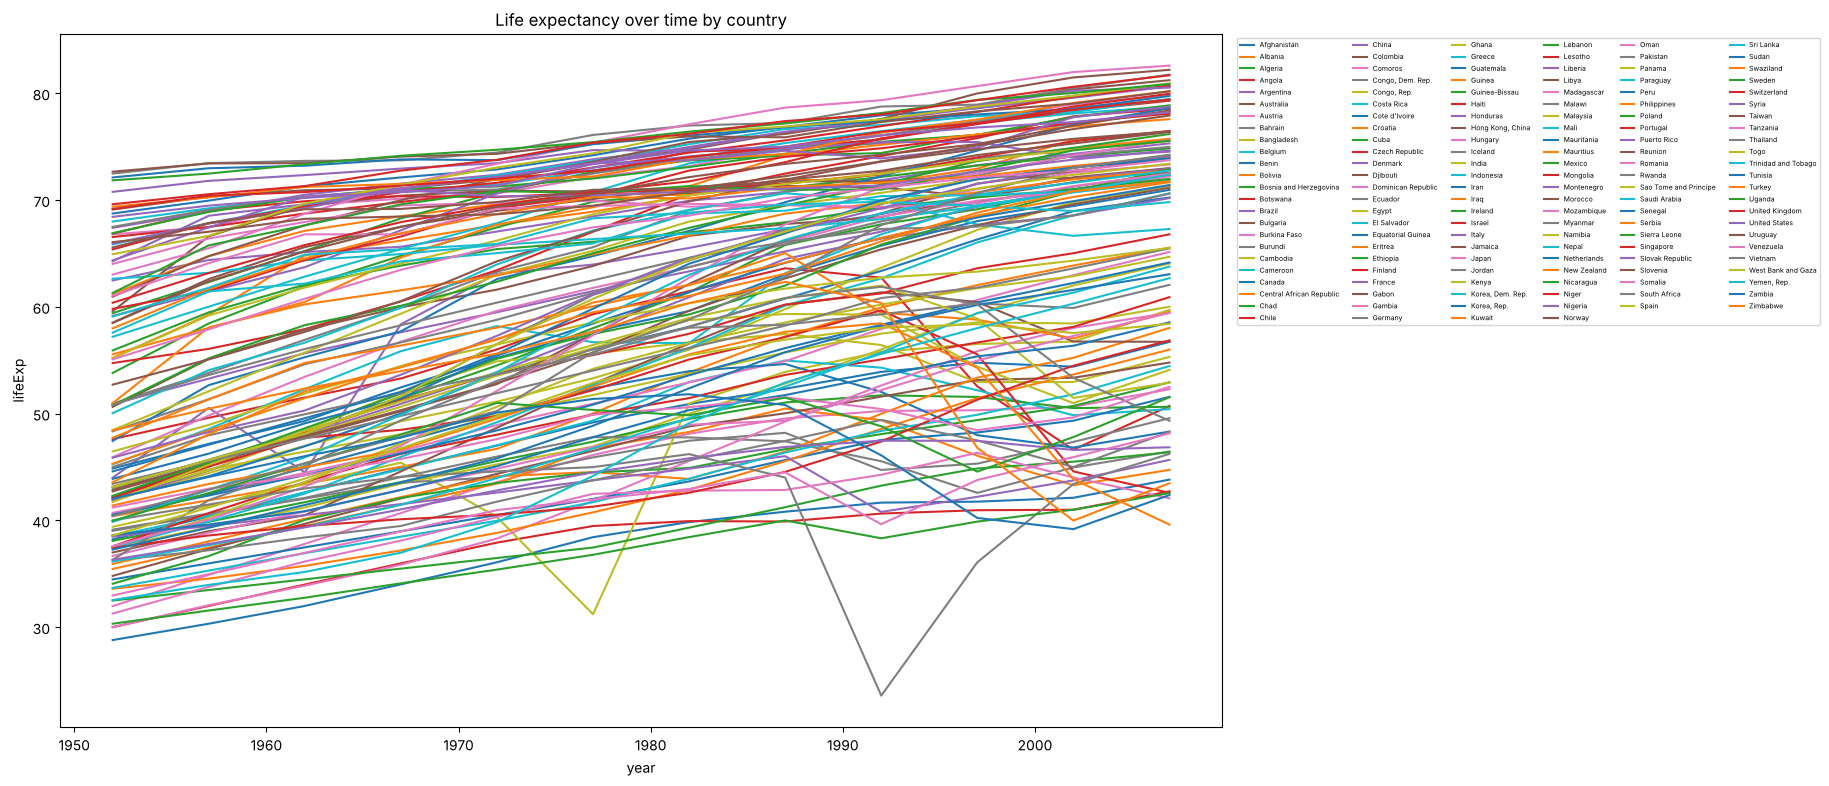

The default colour cycle has 10 colours for 142 lines, so each colour is shared by about 14 countries.


In [2]:
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(15, 9))
    for name, d in df.groupby("country"):
        ax.plot(d["year"], d["lifeExp"], label=name)
    ax.set_title("Life expectancy over time by country")
    ax.set_xlabel("year")
    ax.set_ylabel("lifeExp")
    ax.legend(ncol=6, fontsize=5, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    plt.show()

n_colours = len(plt.rcParamsDefault["axes.prop_cycle"])
print(f"The default colour cycle has {n_colours} colours for {df['country'].nunique()} lines, so each colour is shared by about {df['country'].nunique() / n_colours:.0f} countries.")

### Everything wrong with this chart
- **Overplotting.** 142 lines pile into one dense band. The eye cannot follow any single country from 1952 to 2007.
- **Colour does not identify anything.** The default cycle has only 10 colours (printed above), so about 14 different countries share every colour. Seeing a blue line tells you almost nothing about which country it is.
- **The legend is unusable.** It has 142 tiny entries and takes up more space than the data. To use it the reader has to match a colour to a name, and that is impossible when 14 names have the same colour.
- **Colour has no meaning.** No variable is mapped to it (for example continent). It is decoration, and misleading decoration, since it suggests the colours differ for a reason.
- **No visual hierarchy.** Every line has the same weight, so nothing tells the reader where to look.
- **No message.** The title only repeats the axes ("Life expectancy over time by country"). It does not tell the reader what to take away.
- **It hides the interesting parts.** The sudden drops, such as Rwanda falling to 23.6 years in 1992, vanish inside the tangle, and so does the general trend.
- **Raw column names as axis labels** (`lifeExp`, `year`), with no units.

## Part 2(a) — Aggregate: one line per continent
Each line is the **population-weighted mean** of life expectancy across the countries in that continent, i.e. the life expectancy of the *average person* on that continent. Every line is labelled directly at its end, so there is no legend.

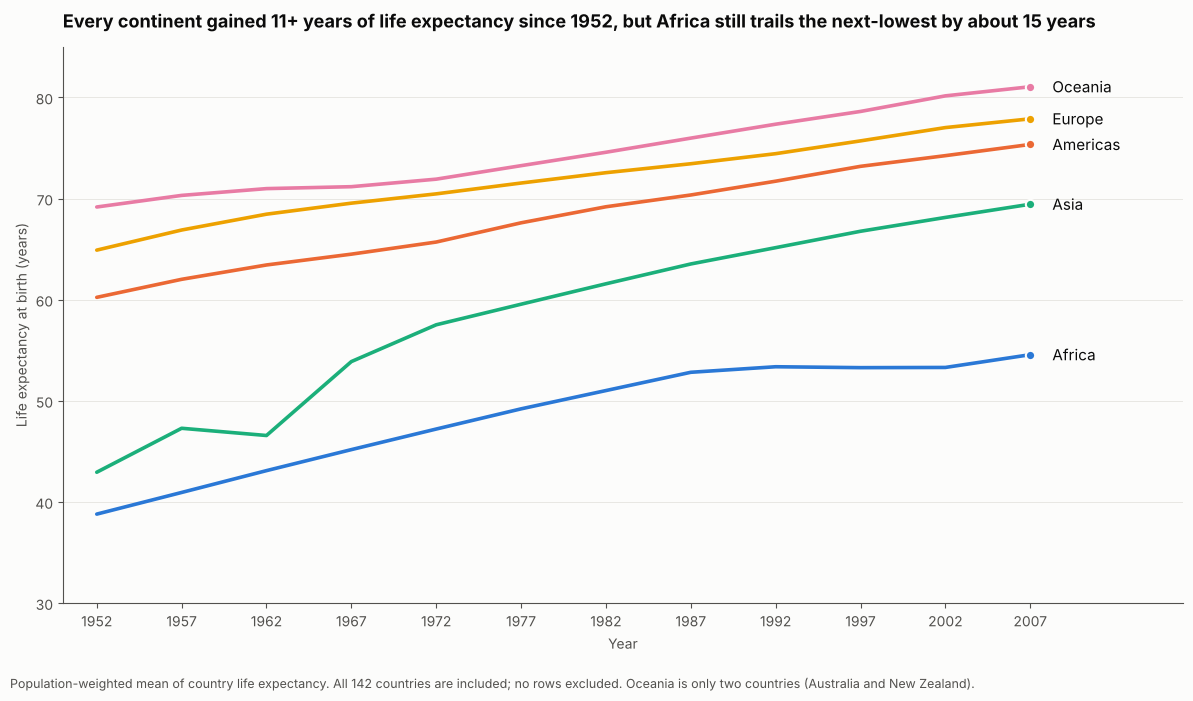

continent,Africa,Americas,Asia,Europe,Oceania
year,,,,,
1952,38.8,60.2,42.9,64.9,69.2
1957,40.9,62.0,47.3,66.9,70.3
1962,43.1,63.4,46.6,68.5,71.0
1967,45.2,64.5,53.9,69.5,71.2
1972,47.2,65.7,57.5,70.5,71.9
1977,49.2,67.6,59.6,71.5,73.3
1982,51.0,69.2,61.6,72.6,74.6
1987,52.8,70.4,63.5,73.4,76.0
1992,53.4,71.7,65.1,74.4,77.4


In [3]:
clean_style()

order = ["Africa", "Americas", "Asia", "Europe", "Oceania"]
cont_colour = dict(zip(order, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))   # fixed order, one colour per continent

cont = (df.groupby(["continent", "year"])
          .apply(lambda d: np.average(d["lifeExp"], weights=d["pop"]), include_groups=False)
          .unstack(0)[order])

gain = cont.loc[2007] - cont.loc[1952]
next_lowest = cont.loc[2007].drop("Africa").min()
gap_africa = next_lowest - cont.loc[2007, "Africa"]

fig, ax = plt.subplots(figsize=(12, 7))
for c in order:
    ax.plot(cont.index, cont[c], color=cont_colour[c], lw=2.6, solid_capstyle="round")
    ax.scatter([2007], [cont.loc[2007, c]], s=45, color=cont_colour[c], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.text(2008.3, cont.loc[2007, c], c, va="center", ha="left", fontsize=11, color=INK)

ax.set_xlim(1950, 2016); ax.set_ylim(30, 85)
ax.set_xticks(range(1952, 2008, 5))
ax.set_xlabel("Year"); ax.set_ylabel("Life expectancy at birth (years)")
ax.set_title(f"Every continent gained {int(np.floor(gain.min()))}+ years of life expectancy since 1952, "
             f"but Africa still trails the next-lowest by about {gap_africa:.0f} years",
             loc="left", fontsize=13, fontweight="bold", pad=14)
fig.text(0.01, 0.01,
         "Population-weighted mean of country life expectancy. All 142 countries are included; no rows excluded. "
         "Oceania is only two countries (Australia and New Zealand).",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

cont.round(1)

**Why this chart?** A line chart is the right form for a measure that changes over ordered time, and aggregating to 5 lines (one per continent) turns an unreadable tangle into a comparison a reader can follow at a glance. Colour now has a job: it identifies the continent, in a fixed order, and each line is labelled directly at its end, so the reader never has to look up a legend. I used the **population-weighted** mean because the question I am answering is "how long does the average person live on that continent?". A plain average of countries would give a small country like Iceland the same say as China. The footnote on the chart says what is aggregated and that Oceania is just two countries, so nobody reads it as a continent-wide picture. The y-axis starts at 30 rather than 0, which is fine for a line chart (it is position, not length, that matters) and uses the space for the 39–81 range of the data.

## Part 2(b) — Highlight: all 142 lines, three in colour
All 142 countries stay on the chart in light grey. I colour only three countries with three *different* stories: **China** (a long climb), **Rwanda** (a sudden collapse) and **Zimbabwe** (a reversal after a long rise). They are labelled directly, with no legend.

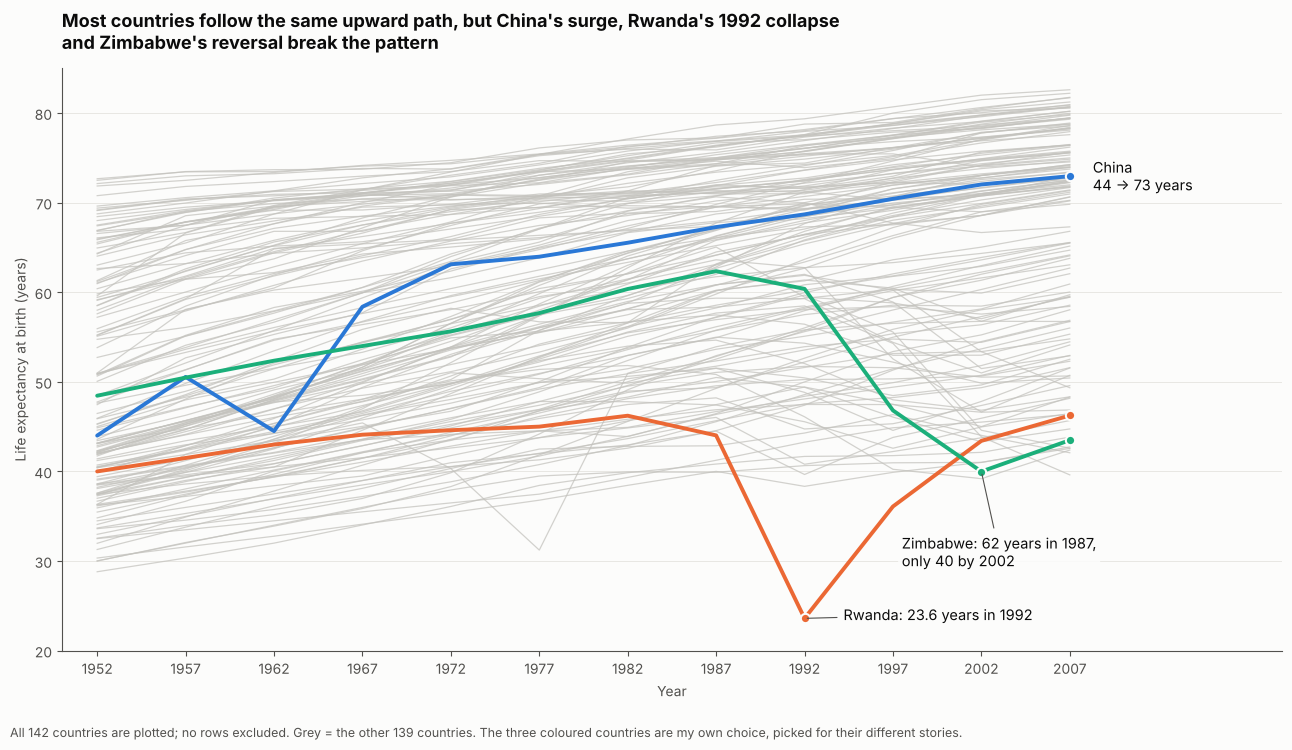

In [4]:
clean_style()

HL = {"China": BLUE, "Rwanda": ORANGE, "Zimbabwe": AQUA}
get = lambda c: df[df["country"] == c].set_index("year")["lifeExp"]

fig, ax = plt.subplots(figsize=(13, 7.5))
for name, d in df.groupby("country"):
    if name not in HL:
        ax.plot(d["year"], d["lifeExp"], color=GREY, lw=0.9, alpha=0.75, zorder=1)
for name, col in HL.items():
    s = get(name)
    ax.plot(s.index, s.values, color=col, lw=2.8, zorder=3, solid_capstyle="round")
    ax.scatter([2007], [s[2007]], s=45, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=4)

box = dict(boxstyle="round,pad=0.25", fc=SURFACE, ec="none", alpha=0.9)
arrow = dict(arrowstyle="-", color=INK2, lw=0.8)

china = get("China")
ax.text(2008.3, china[2007], f"China\n{china[1952]:.0f} → {china[2007]:.0f} years", va="center", ha="left", fontsize=10.5, color=INK)

rw = get("Rwanda")
ax.scatter([1992], [rw[1992]], s=45, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4)
ax.annotate(f"Rwanda: {rw[1992]:.1f} years in 1992", xy=(1992, rw[1992]), xytext=(1994.2, 24.0),
            va="center", ha="left", fontsize=10.5, color=INK, arrowprops=arrow, bbox=box, zorder=5)

zw = get("Zimbabwe")
ax.scatter([2002], [zw[2002]], s=45, color=AQUA, edgecolor=SURFACE, linewidth=1.5, zorder=4)
ax.annotate(f"Zimbabwe: {zw[1987]:.0f} years in 1987,\nonly {zw[2002]:.0f} by 2002", xy=(2002, zw[2002]), xytext=(1997.5, 31.0),
            va="center", ha="left", fontsize=10.5, color=INK, arrowprops=arrow, bbox=box, zorder=5)

ax.set_xlim(1950, 2019); ax.set_ylim(20, 85)
ax.set_xticks(range(1952, 2008, 5))
ax.set_xlabel("Year"); ax.set_ylabel("Life expectancy at birth (years)")
ax.set_title("Most countries follow the same upward path, but China's surge, Rwanda's 1992 collapse\nand Zimbabwe's reversal break the pattern",
             loc="left", fontsize=13, fontweight="bold", pad=14)
fig.text(0.01, 0.01,
         "All 142 countries are plotted; no rows excluded. Grey = the other 139 countries. "
         "The three coloured countries are my own choice, picked for their different stories.",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Why this chart?** Here the question is "how does one country's path compare with everyone else's?", so I keep every country on the chart as a grey **context** layer and use colour only where it carries meaning: the three countries I am talking about. The grey band lets the reader see how unusual each highlighted line is, which a continent average cannot show. Direct labels sit on the interesting point of each line (the 1992 low for Rwanda, the 2002 low for Zimbabwe, the end point for China) instead of a legend, because the label says *what the reader should look at*. The footnote says all 142 countries are plotted and that the three highlights were my choice, so the reader knows the selection is editorial.

## Part 3 — Comparing (a) and (b)
**What (a), the continent lines, shows that (b) cannot**
- The **typical person's** trajectory in each region and the **size of the gaps between regions**: Asia has the biggest gain (about 27 years) and Europe and Oceania the smallest (13 and 12), because they started highest.
- A **trend that no single country shows on its own**: Africa's line is almost flat from 1992 to 2002 (53.4, 53.3, 53.3 years), after rising by about 2 years every 5 years before that. In (b) you cannot see this, because individual lines are too noisy to read a regional pattern from.
- A readable, almost legend-free comparison between groups, which (b) does not attempt at all.

**What (b), the highlighted lines, shows that (a) cannot**
- The **spread inside each group.** In 1952 life expectancy ranged from 28.8 years (Afghanistan) to 72.7 (Norway), and in 2007 from 39.6 (Swaziland) to 82.6 (Japan). A continent average hides all of this.
- **Individual events that an average washes out.** Rwanda's fall to 23.6 years in 1992 is dramatic in (b), but in (a) it is invisible: Rwanda was about 1% of Africa's population in 1992, so the Africa line barely moves (52.8 → 53.4 between 1987 and 1992). Zimbabwe is one of only two countries with a *lower* life expectancy in 2007 than in 1952, and (a) does not show that either.
- **Context for a story.** A grey crowd makes it obvious that China's climb is faster than almost everyone's, which a bare line would not.

**Weaknesses of each.** (a) depends on a choice I made (weighting by population; with a plain average the 1952 Americas value would be 53 instead of 60 and Asia 46 instead of 43), and "Oceania" is just two countries. (b) depends on *which three* countries I picked, and the 139 grey lines cannot be told apart. (a) is the better choice for "how do regions compare?" and (b) for "how unusual is this country?". Neither answers the other's question, so in practice I would use both.

## Part 4 — Has the gap between the richest and poorest countries narrowed since 1952?
Before answering, I look at `gdpPercap`, because the warning in the brief is that it is extremely skewed.

### 4.1 The histogram, linear vs log axis

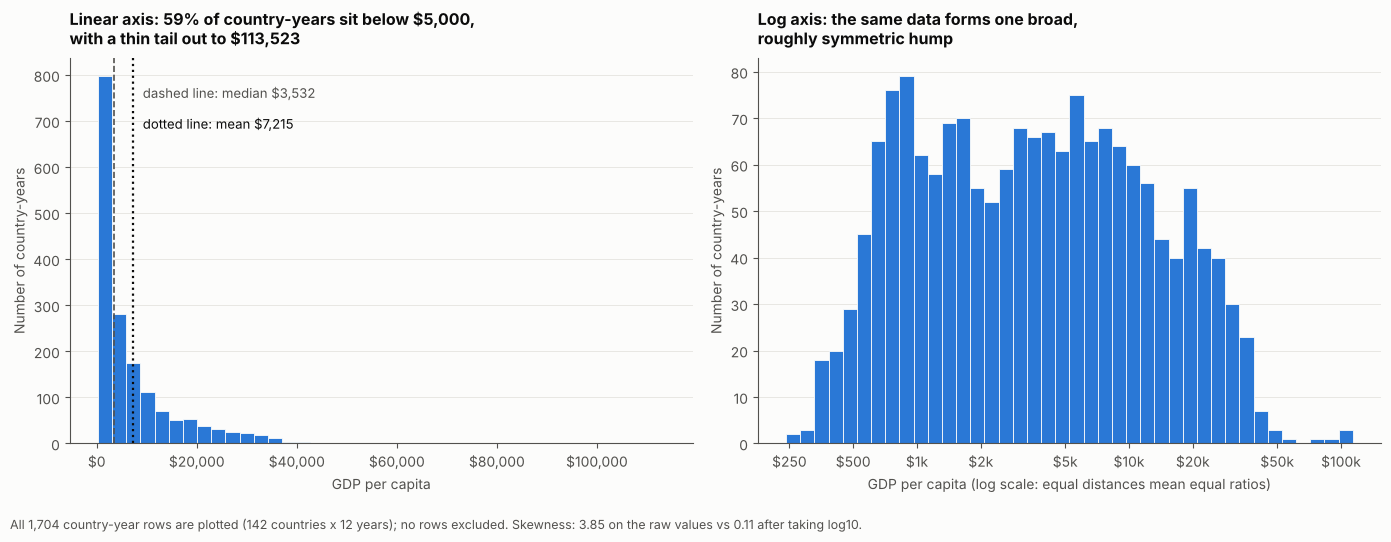

skew raw = 3.85, skew log10 = 0.11; mean $7,215 vs median $3,532; max/min = 471x


In [5]:
clean_style()
g = df["gdpPercap"]
skew_raw, skew_log = g.skew(), np.log10(g).skew()
share_below_5k = (g < 5000).mean()

dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

# Left: linear axis
ax = axes[0]
ax.hist(g, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(g.median(), color=INK2, ls="--", lw=1.2)
ax.axvline(g.mean(), color=INK, ls=":", lw=1.6)
ytop = ax.get_ylim()[1]
ax.text(g.mean() + 2000, ytop * 0.93, f"dashed line: median ${g.median():,.0f}", ha="left", va="top", fontsize=9.5, color=INK2)
ax.text(g.mean() + 2000, ytop * 0.85, f"dotted line: mean ${g.mean():,.0f}", ha="left", va="top", fontsize=9.5, color=INK)
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("GDP per capita"); ax.set_ylabel("Number of country-years")
ax.set_title(f"Linear axis: {share_below_5k:.0%} of country-years sit below $5,000,\nwith a thin tail out to ${g.max():,.0f}",
             loc="left", fontsize=11.5, fontweight="bold", pad=10)

# Right: log axis, log-spaced bins
ax = axes[1]
bins = np.logspace(np.log10(g.min()), np.log10(g.max()), 41)
ax.hist(g, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xscale("log")
ticks = [250, 500, 1000, 2000, 5000, 10000, 20000, 50000, 100000]
ax.set_xticks(ticks); ax.set_xticklabels(["$250", "$500", "$1k", "$2k", "$5k", "$10k", "$20k", "$50k", "$100k"])
ax.minorticks_off()
ax.set_xlabel("GDP per capita (log scale: equal distances mean equal ratios)"); ax.set_ylabel("Number of country-years")
ax.set_title("Log axis: the same data forms one broad,\nroughly symmetric hump",
             loc="left", fontsize=11.5, fontweight="bold", pad=10)

fig.text(0.01, 0.01,
         f"All 1,704 country-year rows are plotted (142 countries x 12 years); no rows excluded. "
         f"Skewness: {skew_raw:.2f} on the raw values vs {skew_log:.2f} after taking log10.",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()
print(f"skew raw = {skew_raw:.2f}, skew log10 = {skew_log:.2f}; mean ${g.mean():,.0f} vs median ${g.median():,.0f}; max/min = {g.max() / g.min():.0f}x")

**What the histograms show.** On the linear axis, most of the data is squeezed into the first few bars (59% of country-years are below $5,000), and a few very rich country-years stretch the axis out to $113,000, so the bars on the right are barely visible. The mean ($7,215) is about twice the median ($3,532), which is what skew does to an average. The skewness statistic is 3.85. After taking logs it drops to 0.11, and the same data forms a single broad hump in which all the structure is visible.

**What a log scale does, and my decision.** On a log axis, equal *distances* are equal *ratios*: going from $500 to $1,000 takes the same space as going from $10,000 to $20,000. That fits how income works (a doubling matters the same at any level) and it spreads the crowded poor end across the chart.
- **I use it for the distribution** above, because on a linear axis the histogram is unreadable. The log axis is labelled in dollars, and its x-axis label says it is log, so nobody misreads it.
- **I do not use it for the final gap chart in 4.2.** That chart shows only two aggregated lines, so the skew is gone, and the question is about the *size* of the gap in dollars. A log axis shows ratios, which would shrink the absolute gap (about $36,000 today) to a small-looking distance. I show the ratio in the annotations instead, so the reader gets both.

### 4.2 How I measure "the gap" (and why the obvious way is misleading)
The first idea is "richest country divided by poorest country". I compute it next to a more robust measure, the **median of the richest 10% of countries versus the median of the poorest 10%** (14 of 142 countries each, re-selected every year).

In [6]:
k = round(0.10 * df["country"].nunique())          # 14 countries = about 10%
rows = []
for year, d in df.groupby("year"):
    s = d.sort_values("gdpPercap")
    rows.append(dict(year=year,
                     poorest_median=s.head(k)["gdpPercap"].median(),
                     richest_median=s.tail(k)["gdpPercap"].median(),
                     poorest=s["gdpPercap"].iloc[0], poorest_country=s["country"].iloc[0],
                     richest=s["gdpPercap"].iloc[-1], richest_country=s["country"].iloc[-1]))
gap = pd.DataFrame(rows).set_index("year")
gap["abs_gap"] = gap["richest_median"] - gap["poorest_median"]
gap["ratio_groups"] = gap["richest_median"] / gap["poorest_median"]
gap["ratio_extremes"] = gap["richest"] / gap["poorest"]

comparison = pd.DataFrame({
    "single richest / single poorest (x)": gap.loc[[1952, 2007], "ratio_extremes"],
    "richest 10% / poorest 10%, medians (x)": gap.loc[[1952, 2007], "ratio_groups"],
    "gap in dollars, richest 10% minus poorest 10%": gap.loc[[1952, 2007], "abs_gap"],
}).round(1)
display(comparison)
print("Single richest/poorest:", gap.loc[1952, ["richest_country", "poorest_country"]].tolist(), "->", gap.loc[2007, ["richest_country", "poorest_country"]].tolist())

# Robustness: keep the 1952 groups fixed instead of re-selecting every year
d52 = df[df["year"] == 1952].sort_values("gdpPercap")
poor52, rich52 = d52.head(k)["country"], d52.tail(k)["country"]
fixed = {y: df[(df["year"] == y) & df["country"].isin(rich52)]["gdpPercap"].median() /
            df[(df["year"] == y) & df["country"].isin(poor52)]["gdpPercap"].median() for y in (1952, 2007)}
print(f"Fixed 1952 groups: ratio {fixed[1952]:.1f}x in 1952 -> {fixed[2007]:.1f}x in 2007")

,single richest / single poorest (x),"richest 10% / poorest 10%, medians (x)","gap in dollars, richest 10% minus poorest 10%"
year,,,
1952,362.7,27.1,9640.7
2007,177.8,55.8,36486.1


Single richest/poorest: ['Kuwait', 'Lesotho'] -> ['Norway', 'Congo, Dem. Rep.']
Fixed 1952 groups: ratio 27.1x in 1952 -> 44.0x in 2007


**Why the obvious measure misleads.** Dividing the single richest country by the single poorest says the gap **narrowed** (about 363× in 1952 to 178× in 2007). That is an artefact of two outliers: in 1952 the richest country was Kuwait at $108,382, about ten times the median of the richest 10% that year (about $10,000), and the extremes also change countries over time (Kuwait and Lesotho in 1952, Norway and the Democratic Republic of the Congo in 2007). The ratio of the two *groups* is much more stable and tells the opposite story, so a single country at each end is a poor basis for the answer.

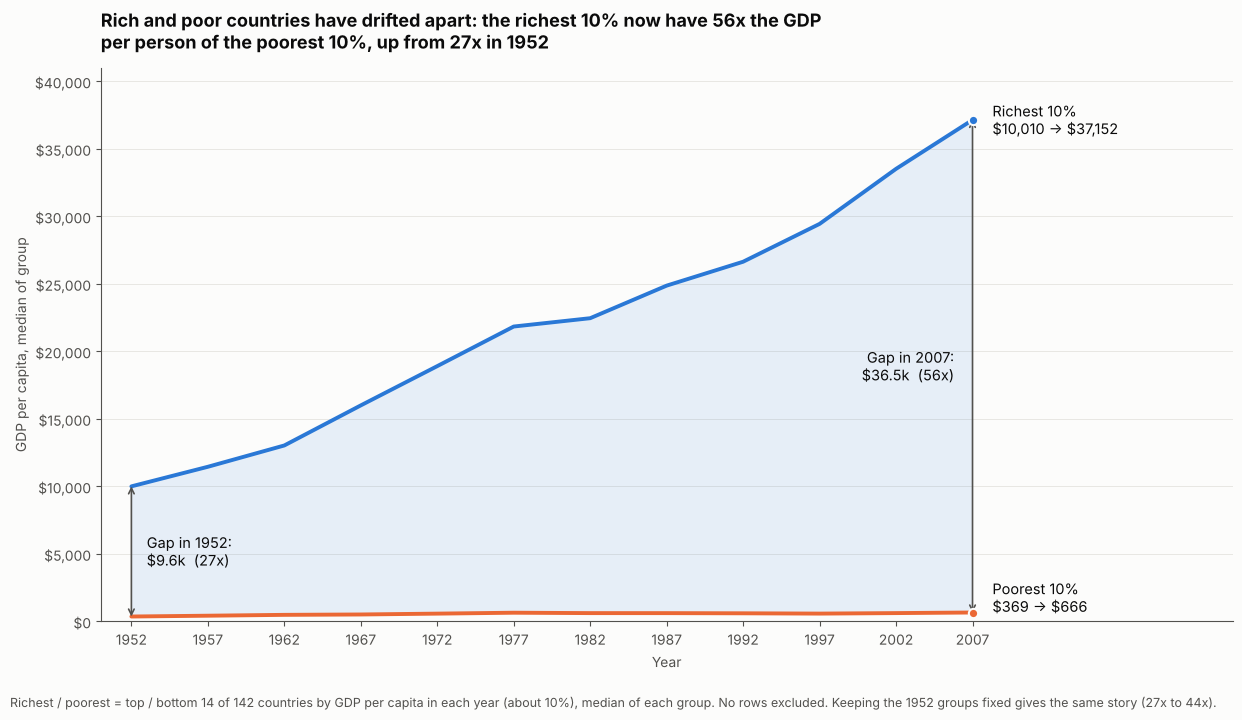

In [7]:
clean_style()

x = gap.index
r52, r07 = gap.loc[1952, "ratio_groups"], gap.loc[2007, "ratio_groups"]
rich, poor = gap["richest_median"], gap["poorest_median"]
money_k = lambda v: f"${v / 1000:,.1f}k"

fig, ax = plt.subplots(figsize=(12.5, 7.2))
ax.fill_between(x, poor, rich, color=BLUE, alpha=0.10, linewidth=0)
ax.plot(x, rich, color=BLUE, lw=2.8, solid_capstyle="round")
ax.plot(x, poor, color=ORANGE, lw=2.8, solid_capstyle="round")
for s, col in ((rich, BLUE), (poor, ORANGE)):
    ax.scatter([2007], [s[2007]], s=45, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=4)

# the gap, drawn at both ends
for yr, dx, ha in ((1952, 1, "left"), (2007, -1.2, "right")):
    ax.annotate("", xy=(yr, poor[yr]), xytext=(yr, rich[yr]),
                arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.2, shrinkA=0, shrinkB=0))
    ax.text(yr + dx, (rich[yr] + poor[yr]) / 2,
            f"Gap in {yr}:\n{money_k(gap.loc[yr, 'abs_gap'])}  ({gap.loc[yr, 'ratio_groups']:.0f}x)",
            ha=ha, va="center", fontsize=10.5, color=INK)

# direct labels at the line ends
ax.text(2008.3, rich[2007], f"Richest 10%\n${rich[1952]:,.0f} → ${rich[2007]:,.0f}", va="center", ha="left", fontsize=10.5, color=INK)
ax.text(2008.3, poor[2007] + 1100, f"Poorest 10%\n${poor[1952]:,.0f} → ${poor[2007]:,.0f}", va="center", ha="left", fontsize=10.5, color=INK)

ax.set_xlim(1950, 2024); ax.set_ylim(0, 41000)
ax.set_xticks(range(1952, 2008, 5))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_xlabel("Year"); ax.set_ylabel("GDP per capita, median of group")
ax.set_title(f"Rich and poor countries have drifted apart: the richest 10% now have {r07:.0f}x the GDP\n"
             f"per person of the poorest 10%, up from {r52:.0f}x in 1952",
             loc="left", fontsize=13, fontweight="bold", pad=14)
fig.text(0.01, 0.01,
         f"Richest / poorest = top / bottom {k} of 142 countries by GDP per capita in each year (about 10%), median of each group. "
         f"No rows excluded. Keeping the 1952 groups fixed gives the same story ({fixed[1952]:.0f}x to {fixed[2007]:.0f}x).",
         fontsize=9, color=INK2)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

**Answer: no, the gap has not narrowed. It has widened.** The richest 10% of countries went from a median of about $10,000 to about $37,000 (up roughly 270%), while the poorest 10% went from about $370 to about $670 (up roughly 80%). The poorest did get richer, but the richest got richer much faster, so the ratio roughly doubled (27× → 56×) and the gap in dollars went from about $9,600 to about $36,500 per person. Keeping the 1952 groups fixed, instead of re-selecting them every year, gives the same direction (27× → 44×), so the result does not depend on who is in each group.

**Why this chart type?**
- **A line chart over time**, because the question is about *change* across 12 ordered time points, and lines show direction and speed of change better than 24 separate bars would.
- **Two aggregated lines, not 142.** The question is about the two ends of the distribution, so I aggregate each end into one line (the median of 14 countries), which also protects the chart from single-country outliers like Kuwait in 1952.
- **The shaded area between the lines is the gap itself.** The reader sees it grow without doing any arithmetic, and the arrows and labels at both ends give the exact values (dollars and ratio), so the chart does not rely on the shading alone.
- **A linear axis starting at $0**, so the vertical distances are honest dollar amounts. A log axis would show the *ratio* but shrink the absolute gap, which is why I printed the ratio on the chart instead (see 4.1).
- **One y-axis, colour with a job** (blue = richest group, orange = poorest group, each also labelled directly, no legend), and the footnote says how the groups are defined and that no rows were excluded.
- **Not a single richest-vs-poorest comparison**, for the reason shown in the table above: it points the wrong way because of outliers.